# P5 – Deteksi Tepi (Praktikum Computer Vision P5-P6, SIMUTEH)
**Nama:** Ramadi Hayqal Dwinugraha · **NIM:** 2230511115 · **Kelas:** 7A · **SEED:** 1115

Notebook ini mengerjakan Bagian 1 (gradien dan operator tepi) dan Bagian 2 (Canny dan keputusan pemakaian tepi).
Jalankan dari atas ke bawah (Runtime → Restart session → Run all). Praproses yang dipakai adalah milik sendiri (`src/praproses.py` dan `hasil/param_praproses.json` dari Evaluasi P1-P4).

In [2]:
from pathlib import Path
import sys, os, re, json

# 1) Pasang Google Drive (khusus Google Colab)
try:
    from google.colab import drive
    if not Path("/content/drive/MyDrive").exists():
        drive.mount("/content/drive")
except ImportError:
    pass

# 2) Cari folder repository simuteh-2230511115 (harus berisi src/ dan data/)
NIM = "2230511115"
DRIVE_NB = Path("/content/drive/MyDrive/Colab Notebooks")
_kand = [DRIVE_NB / f"simuteh-{NIM}", DRIVE_NB / f"simuteh-{NIM}" / f"simuteh-{NIM}",
         Path.cwd(), *Path.cwd().parents, Path(f"/content/simuteh-{NIM}")]
if DRIVE_NB.exists():
    _kand += sorted(DRIVE_NB.glob(f"*/simuteh-{NIM}"))
ROOT = next((p.resolve() for p in _kand
             if (p / "src" / "utils_cv.py").is_file() and (p / "data" / "sintetis" / "label.csv").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Folder simuteh-2230511115 (berisi src/, data/, hasil/) belum ditemukan di "
                            "Drive Saya/Colab Notebooks. Unggah folder utuh, bukan hanya file .ipynb.")
os.chdir(ROOT / "notebook")              # semua jalur relatif pada petunjuk ("../src", "../hasil") berlaku
sys.path.insert(0, str(ROOT / "src"))

# 3) Periksa SEED = 4 digit terakhir NIM
SEED = int(re.search(r"^SEED\s*=\s*(\d+)", (ROOT / "src" / "buat_dataset_sintetis.py").read_text(), re.M).group(1))
assert str(SEED) == NIM[-4:], f"SEED {SEED} tidak sama dengan 4 digit terakhir NIM {NIM[-4:]}"
print("Repository:", ROOT, "| SEED =", SEED)

Mounted at /content/drive
Repository: /content/drive/MyDrive/Colab Notebooks/simuteh-2230511115 | SEED = 1115


## Bagian 1. Gradien citra dan operator tepi
### Langkah 1.1 Lembar hitung manual (diverifikasi dengan kode)

In [3]:
import numpy as np
A = np.array([[52, 55, 180], [50, 58, 185], [54, 60, 190]], float)
Kx = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], float); Ky = Kx.T
Px = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], float); Py = Px.T
Lap = np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]], float)
for nama, kx, ky in [("Sobel", Kx, Ky), ("Prewitt", Px, Py)]:
    gx, gy = (A * kx).sum(), (A * ky).sum()
    print(f"{nama}: Gx={gx:.0f} Gy={gy:.0f} |G|={np.hypot(gx, gy):.2f} |Gx|+|Gy|={abs(gx)+abs(gy):.0f} "
          f"theta={np.degrees(np.arctan2(gy, gx)):.2f} derajat")
print("Rasio magnitudo Sobel/Prewitt:", round(np.hypot((A*Kx).sum(), (A*Ky).sum()) / np.hypot((A*Px).sum(), (A*Py).sum()), 3))
print("Laplacian pusat:", (A * Lap).sum())

Sobel: Gx=534 Gy=22 |G|=534.45 |Gx|+|Gy|=556 theta=2.36 derajat
Prewitt: Gx=399 Gy=17 |G|=399.36 |Gx|+|Gy|=416 theta=2.44 derajat
Rasio magnitudo Sobel/Prewitt: 1.338
Laplacian pusat: 118.0


### Langkah 1.2 Persiapan dan gradien Sobel (Kode 1.1 dan 1.2)

Memperbarui sinkronisasi file Google Drive...
PARAM praproses: {'lebar': 640, 'gamma': 1.0, 'clahe_clip': 2.0, 'clahe_tile': 8, 'penapis': 'rerata', 'kernel': 5, 'sigma': 1.0, 'tajam_k': 0.0}


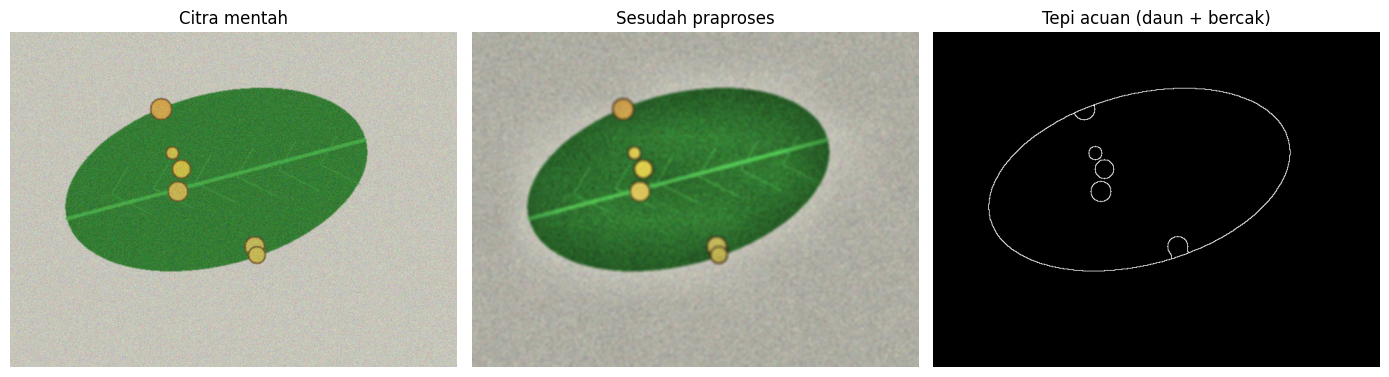

In [4]:
import sys, os
from pathlib import Path
import importlib

# Memaksa sinkronisasi ulang sistem file Google Drive agar file baru terdeteksi
try:
    from google.colab import drive
    print("Memperbarui sinkronisasi file Google Drive...")
    if not Path("/content/drive/MyDrive").exists():
        drive.mount("/content/drive", force_remount=True)
except ImportError:
    pass

# Definisikan ulang ROOT secara absolut dan tambahkan direktori src ke sys.path
ROOT = Path("/content/drive/MyDrive/Colab Notebooks/simuteh-2230511115")
os.chdir(ROOT / "notebook")
path_src = str((ROOT / "src").resolve())

if path_src not in sys.path:
    sys.path.insert(0, path_src)

# Bersihkan cache pencarian modul Python agar mendeteksi file baru
importlib.invalidate_caches()

import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt, json
from utils_cv import baca, tampil
from praproses import praproses
from utils_tepi import tepi_acuan, skor_tepi, iou, mask_daun_awal, bercak_awal

pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)
PARAM = json.load(open("../hasil/param_praproses.json"))   # hasil Evaluasi P1-P4
label = pd.read_csv("../data/sintetis/label.csv")

def muat(nama):
    img = baca(f"../data/sintetis/citra/{nama}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
    mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
    return img, md, mb

img, md, mb = muat("teh_041.png")
pra = praproses(img, PARAM)
acuan = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
tampil([img, pra, acuan], ["Citra mentah", "Sesudah praproses", "Tepi acuan (daun + bercak)"])
print("PARAM praproses:", PARAM)

selisih maks gx manual vs cv2.Sobel: 0.0
magnitudo maks: 315.6


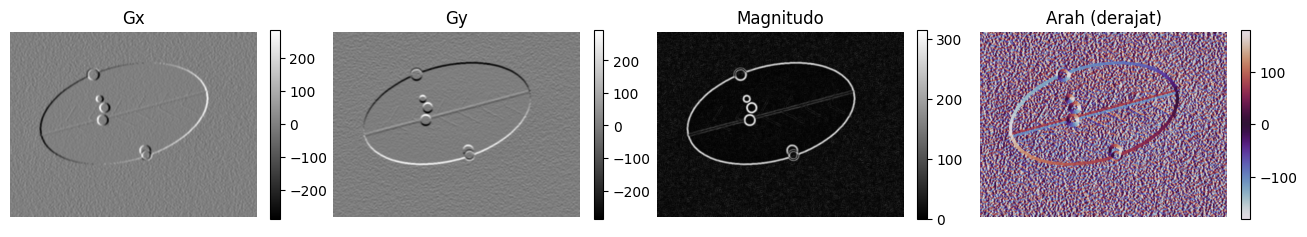

In [5]:
g = pra[:, :, 2].astype(np.float32)          # kanal R hasil praproses
kx = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], np.float32)
ky = kx.T
gx = cv2.filter2D(g, cv2.CV_32F, kx)          # turunan arah x (tepi vertikal)
gy = cv2.filter2D(g, cv2.CV_32F, ky)          # turunan arah y (tepi horizontal)
mag = np.sqrt(gx ** 2 + gy ** 2)
arah = np.degrees(np.arctan2(gy, gx))
gx_cv = cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=3)
print("selisih maks gx manual vs cv2.Sobel:", np.abs(gx - gx_cv).max())
print("magnitudo maks:", mag.max().round(1))
plt.figure(figsize=(16, 3.6))
for i, (c, jd) in enumerate([(gx, "Gx"), (gy, "Gy"), (mag, "Magnitudo"), (arah, "Arah (derajat)")]):
    plt.subplot(1, 4, i + 1); plt.imshow(c, cmap="twilight" if i == 3 else "gray")
    plt.title(jd); plt.axis("off"); plt.colorbar(fraction=0.035)
plt.savefig("../hasil/p5_gradien_panel.png", dpi=130, bbox_inches="tight")

### Langkah 1.3 Empat operator pada satu citra (Kode 1.3)

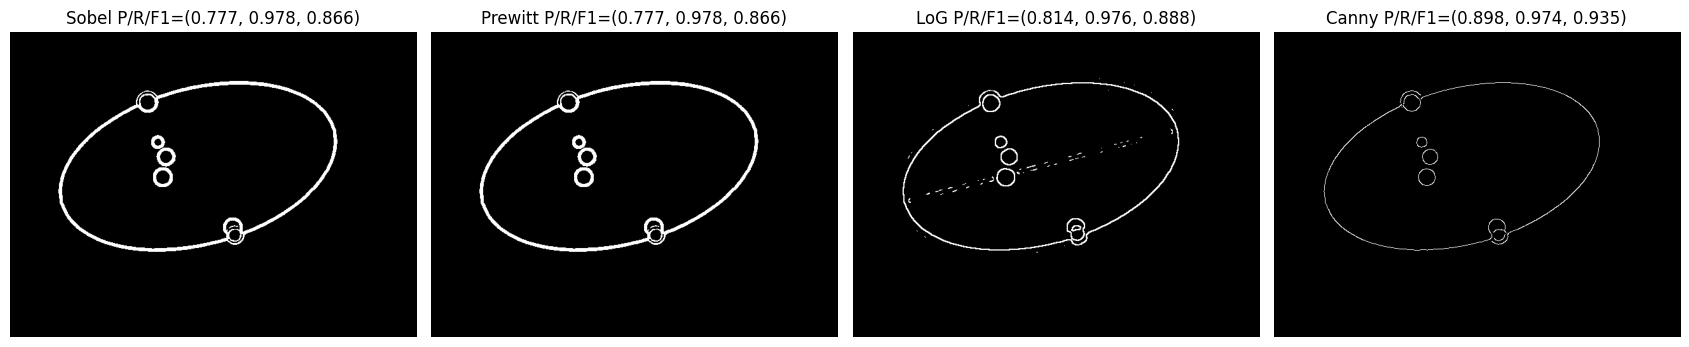

In [6]:
def tepi_sobel(g, T=100):
    g = g.astype(np.float32)
    m = np.hypot(cv2.Sobel(g, cv2.CV_32F, 1, 0), cv2.Sobel(g, cv2.CV_32F, 0, 1))
    return ((m > T) * 255).astype(np.uint8)

def tepi_prewitt(g, T=75):
    kx = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], np.float32)
    g = g.astype(np.float32)
    m = np.hypot(cv2.filter2D(g, -1, kx), cv2.filter2D(g, -1, kx.T))
    return ((m > T) * 255).astype(np.uint8)

def tepi_log(g, sigma=3.0, frac=0.2):
    """Laplacian of Gaussian: tepi = perlintasan nol yang cukup kuat."""
    L = cv2.Laplacian(cv2.GaussianBlur(g.astype(np.float32), (0, 0), sigma), cv2.CV_32F)
    mn, mx = cv2.erode(L, np.ones((3, 3))), cv2.dilate(L, np.ones((3, 3)))
    return (((mn < 0) & (mx > 0) & (mx - mn > frac * np.abs(L).max())) * 255).astype(np.uint8)

def tepi_canny(g, lo=30, hi=90, sigma=2.0):
    if sigma > 0:
        g = cv2.GaussianBlur(g, (0, 0), sigma)
    return cv2.Canny(g, lo, hi)

metode = {"Sobel": tepi_sobel, "Prewitt": tepi_prewitt, "LoG": tepi_log, "Canny": tepi_canny}
g = pra[:, :, 2]
hasil = {nm: f(g) for nm, f in metode.items()}
tampil(list(hasil.values()), [f"{nm} P/R/F1={skor_tepi(e, acuan)}" for nm, e in hasil.items()], ukuran=(17, 3.6))
plt.savefig("../hasil/p5_empat_operator.png", dpi=130, bbox_inches="tight")

### Langkah 1.4 Perbandingan menyeluruh (Kode 1.4) → Tabel 6

In [7]:
baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    ac = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
    for sumber, im in [("mentah", img), ("praproses", praproses(img, PARAM))]:
        for kanal, g in [("Gray", cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)), ("R", im[:, :, 2])]:
            for nm, f in metode.items():
                p, r, f1 = skor_tepi(f(g), ac)
                baris.append([d.kondisi_cahaya, sumber, kanal, nm, p, r, f1])
tabel_tepi = pd.DataFrame(baris, columns=["kondisi", "sumber", "kanal", "metode", "P", "R", "F1"])
ringkas = tabel_tepi.groupby(["sumber", "kanal", "metode"])[["P", "R", "F1"]].mean().round(3)
print(ringkas)
tabel_tepi.to_csv("../hasil/p5_tabel_tepi.csv", index=False)
print("\nTabel 6 (rerata F1):")
t6 = tabel_tepi.pivot_table(index="metode", columns=["sumber", "kanal"], values="F1").round(3).loc[list(metode)]
print(t6)
t6.to_csv("../hasil/p5_tabel6_f1.csv")

                             P      R     F1
sumber    kanal metode                      
mentah    Gray  Canny    0.758  0.758  0.757
                LoG      0.638  0.996  0.774
                Prewitt  0.783  0.957  0.852
                Sobel    0.745  0.965  0.828
          R     Canny    0.983  0.973  0.977
                LoG      0.908  0.996  0.945
                Prewitt  0.502  0.994  0.618
                Sobel    0.433  0.995  0.551
praproses Gray  Canny    0.786  0.926  0.841
                LoG      0.614  0.995  0.757
                Prewitt  0.828  0.961  0.880
                Sobel    0.826  0.962  0.880
          R     Canny    0.975  0.985  0.980
                LoG      0.902  0.996  0.943
                Prewitt  0.843  0.995  0.911
                Sobel    0.843  0.995  0.912

Tabel 6 (rerata F1):
sumber  mentah        praproses       
kanal     Gray      R      Gray      R
metode                                
Sobel    0.828  0.551     0.880  0.912
Prewitt  0.8

### Langkah 1.5 Grafik F1 per kondisi cahaya (Kerjakan sendiri)

metode          Sobel  Prewitt    LoG  Canny
kondisi                                     
normal          0.891    0.891  0.957  0.978
gelap           0.871    0.871  0.980  0.982
terang          0.916    0.916  0.926  0.975
kontras_rendah  0.968    0.968  0.898  0.978
bayangan        0.912    0.911  0.956  0.987


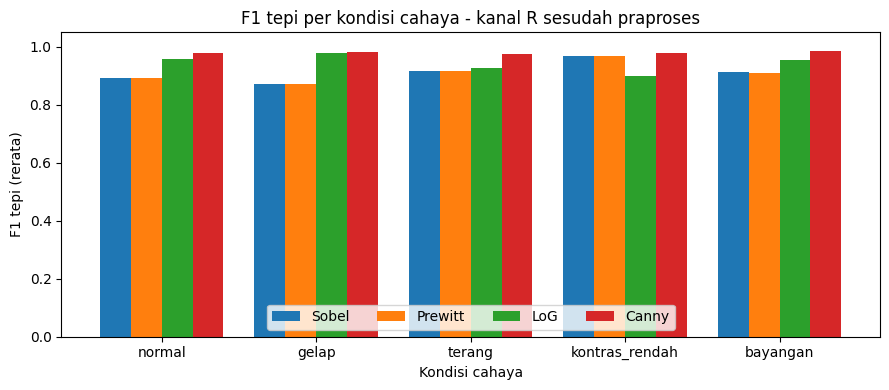

In [8]:
urut = ["normal", "gelap", "terang", "kontras_rendah", "bayangan"]
f = (tabel_tepi[(tabel_tepi.sumber == "praproses") & (tabel_tepi.kanal == "R")]
     .groupby(["kondisi", "metode"]).F1.mean().unstack().loc[urut, list(metode)])
print(f.round(3))
ax = f.plot.bar(figsize=(9, 4), width=0.8)
ax.set_ylabel("F1 tepi (rerata)"); ax.set_xlabel("Kondisi cahaya"); ax.set_ylim(0, 1.05)
ax.set_title("F1 tepi per kondisi cahaya - kanal R sesudah praproses")
plt.xticks(rotation=0); plt.legend(ncol=4, loc="lower center"); plt.tight_layout()
plt.savefig("../hasil/p5_f1_kondisi.png", dpi=160, bbox_inches="tight")

## Bagian 2. Algoritma Canny dan keputusan pemakaian tepi
### Langkah 2.1 Lembar hitung manual NMS dan hysteresis (diverifikasi dengan kode)

In [9]:
M1 = np.array([[30, 40, 35], [90, 100, 95], [20, 30, 25]], float)
M2 = np.array([[50, 60, 55], [85, 80, 70], [40, 45, 50]], float)
def nms(M, arah):
    c = M[1, 1]
    a, b = (M[1, 0], M[1, 2]) if arah == 0 else (M[0, 1], M[2, 1])   # tetangga searah gradien
    return ("dipertahankan" if c >= a and c >= b else "ditekan (0)"), a, b
for nm, M in [("M1", M1), ("M2", M2)]:
    for ar in (0, 90):
        print(nm, "arah gradien", ar, "derajat ->", nms(M, ar))
v = np.array([20, 60, 120, 80, 40, 90, 30]); lo, hi = 50, 100
kuat = v >= hi; lemah = (v >= lo) & (v < hi)
akhir = kuat.copy()
for _ in range(len(v)):                      # rambatkan dari piksel kuat ke tetangga lemah
    for i in range(len(v)):
        if lemah[i] and ((i > 0 and akhir[i - 1]) or (i < len(v) - 1 and akhir[i + 1])):
            akhir[i] = True
print("kuat :", kuat.astype(int)); print("lemah:", lemah.astype(int)); print("akhir:", akhir.astype(int))

M1 arah gradien 0 derajat -> ('dipertahankan', np.float64(90.0), np.float64(95.0))
M1 arah gradien 90 derajat -> ('dipertahankan', np.float64(40.0), np.float64(30.0))
M2 arah gradien 0 derajat -> ('ditekan (0)', np.float64(85.0), np.float64(70.0))
M2 arah gradien 90 derajat -> ('dipertahankan', np.float64(60.0), np.float64(45.0))
kuat : [0 0 1 0 0 0 0]
lemah: [0 1 0 1 0 1 0]
akhir: [0 1 1 1 0 0 0]


### Langkah 2.2 Pengaruh sigma dan ambang (Kode 2.1) → Tabel 7

In [10]:
baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    g = praproses(img, PARAM)[:, :, 2]
    ad, ab = tepi_acuan(md), tepi_acuan(mb)
    ac = cv2.bitwise_or(ad, ab)
    for sigma in [0, 1.0, 2.0]:
        for lo, hi in [(30, 90), (50, 150), (100, 200)]:
            e = tepi_canny(g, lo, hi, sigma)
            p, r, f1 = skor_tepi(e, ac)
            r_bercak = skor_tepi(e, ab)[1]       # recall khusus tepi bercak
            baris.append([d.kelas, sigma, f"{lo}/{hi}", p, r, f1, r_bercak])
canny = pd.DataFrame(baris, columns=["kelas", "sigma", "ambang", "P", "R", "F1", "R_bercak"])
print(canny.groupby(["sigma", "ambang"])[["P", "R", "F1", "R_bercak"]].mean().round(3))
t7 = canny.pivot_table(index=["sigma", "ambang"], columns="kelas", values="R_bercak").round(3)
print(t7)
canny.to_csv("../hasil/p5_eksperimen_canny.csv", index=False)

                   P      R     F1  R_bercak
sigma ambang                                
0.0   100/200  0.975  0.947  0.957     0.899
      30/90    0.560  0.989  0.673     0.958
      50/150   0.967  0.988  0.977     0.955
1.0   100/200  0.933  0.891  0.900     0.787
      30/90    0.865  0.991  0.917     0.967
      50/150   0.974  0.989  0.981     0.958
2.0   100/200  0.794  0.763  0.777     0.610
      30/90    0.975  0.985  0.980     0.931
      50/150   0.931  0.890  0.898     0.757
kelas          berat  ringan
sigma ambang                
0.0   100/200  0.925   0.874
      30/90    0.951   0.965
      50/150   0.949   0.961
1.0   100/200  0.793   0.780
      30/90    0.956   0.977
      50/150   0.953   0.963
2.0   100/200  0.636   0.585
      30/90    0.927   0.936
      50/150   0.762   0.752


### Langkah 2.3 Ambang otomatis berbasis median (Kode 2.2)

In [11]:
def canny_otomatis(g, s=0.33):
    """Ambang dari median intensitas: bawah = (1-s) x median, atas = (1+s) x median."""
    v = np.median(g)
    return cv2.Canny(g, int(max(0, (1 - s) * v)), int(min(255, (1 + s) * v)))

baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    ac = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
    pra_ = praproses(img, PARAM)
    for kanal, g in [("Gray", cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)), ("R", pra_[:, :, 2])]:
        baris.append([d.kondisi_cahaya, kanal, "otomatis", skor_tepi(canny_otomatis(g), ac)[2], np.median(g)])
        baris.append([d.kondisi_cahaya, kanal, "tetap 30/90", skor_tepi(tepi_canny(g), ac)[2], np.median(g)])
auto = pd.DataFrame(baris, columns=["kondisi", "kanal", "ambang", "F1", "median"])
print(auto.pivot_table(index=["kanal", "ambang"], columns="kondisi", values="F1").round(3))
print(auto.groupby(["kanal", "kondisi"])["median"].mean().round(1))

kondisi            bayangan  gelap  kontras_rendah  normal  terang
kanal ambang                                                      
Gray  otomatis        0.881  0.912           0.331   0.951   0.707
      tetap 30/90     0.876  0.764           0.922   0.774   0.870
R     otomatis        0.986  0.982           0.843   0.978   0.979
      tetap 30/90     0.987  0.982           0.978   0.978   0.975
kanal  kondisi       
Gray   bayangan          117.0
       gelap             135.1
       kontras_rendah    150.2
       normal            172.8
       terang            198.6
R      bayangan          120.0
       gelap             152.6
       kontras_rendah    154.4
       normal            177.5
       terang            205.5
Name: median, dtype: float64


Bukti untuk P2.3: ambang otomatis yang dihitung dari median dibandingkan dengan besar gradien (Sobel) di tepi daun pada citra kontras rendah.

In [12]:
baris = []
for _, d in label[(label.kelas != "sehat") & (label.kondisi_cahaya.isin(["kontras_rendah", "normal"]))].iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    ed = tepi_acuan(md) > 0
    for kanal, g in [("Gray", cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)), ("R", pra_[:, :, 2])]:
        gf = cv2.GaussianBlur(g, (0, 0), 2.0).astype(np.float32)
        m = np.hypot(cv2.Sobel(gf, cv2.CV_32F, 1, 0), cv2.Sobel(gf, cv2.CV_32F, 0, 1))
        v = np.median(g)
        baris.append([d.kondisi_cahaya, kanal, round(v, 1), int((1 - .33) * v), int((1 + .33) * v),
                      round(float(np.median(m[ed])), 1), round(float(np.percentile(m[ed], 90)), 1)])
tg = pd.DataFrame(baris, columns=["kondisi", "kanal", "median_intensitas", "lo_otomatis", "hi_otomatis",
                                  "gradien_tepi_daun_median", "gradien_tepi_daun_p90"])
print(tg.groupby(["kondisi", "kanal"]).mean().round(1))

                      median_intensitas  lo_otomatis  hi_otomatis  gradien_tepi_daun_median  gradien_tepi_daun_p90
kondisi        kanal                                                                                              
kontras_rendah Gray               150.2        100.1        199.4                      72.4                   80.7
               R                  154.4        102.9        204.9                      91.9                  100.4
normal         Gray               172.8        115.2        229.2                     130.4                  139.0
               R                  177.5        118.1        235.9                     172.5                  181.2


### Langkah 2.4 Ambang persentil (Kerjakan sendiri): `canny_persentil`

In [13]:
def canny_persentil(g, q, rasio=0.4, sigma=2.0):
    """Canny dengan ambang atas = persentil ke-q magnitudo Sobel, ambang bawah = rasio x ambang atas."""
    gh = cv2.GaussianBlur(g, (0, 0), sigma) if sigma > 0 else g            # (1) haluskan
    gf = gh.astype(np.float32)
    mag = np.hypot(cv2.Sobel(gf, cv2.CV_32F, 1, 0), cv2.Sobel(gf, cv2.CV_32F, 0, 1))   # (2) magnitudo
    atas = float(np.percentile(mag, q)); bawah = rasio * atas                # (3) ambang dari persentil
    return cv2.Canny(gh, bawah, atas, L2gradient=True)                       # (4) Canny (skala L2 = hypot)

baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    ac = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
    pra_ = praproses(img, PARAM)
    for kanal, g in [("Gray", cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)), ("R", pra_[:, :, 2])]:
        for q in (90, 95, 98):
            baris.append([d.kondisi_cahaya, kanal, f"persentil {q}", skor_tepi(canny_persentil(g, q), ac)[2]])
        baris.append([d.kondisi_cahaya, kanal, "otomatis (median)", skor_tepi(canny_otomatis(g), ac)[2]])
        baris.append([d.kondisi_cahaya, kanal, "tetap 30/90", skor_tepi(tepi_canny(g), ac)[2]])
cp = pd.DataFrame(baris, columns=["kondisi", "kanal", "ambang", "F1"])
tcp = cp.pivot_table(index=["kanal", "ambang"], columns="kondisi", values="F1").round(3)
tcp["rerata"] = tcp.mean(axis=1).round(3)
print(tcp)
tcp.to_csv("../hasil/p5_canny_persentil.csv")

kondisi                  bayangan  gelap  kontras_rendah  normal  terang  rerata
kanal ambang                                                                    
Gray  otomatis (median)     0.881  0.912           0.331   0.951   0.707   0.756
      persentil 90          0.105  0.108           0.085   0.112   0.095   0.101
      persentil 95          0.630  0.656           0.483   0.639   0.596   0.601
      persentil 98          0.827  0.869           0.848   0.816   0.790   0.830
      tetap 30/90           0.876  0.764           0.922   0.774   0.870   0.841
R     otomatis (median)     0.986  0.982           0.843   0.978   0.979   0.954
      persentil 90          0.106  0.099           0.093   0.104   0.098   0.100
      persentil 95          0.594  0.495           0.488   0.690   0.630   0.579
      persentil 98          0.990  0.981           0.976   0.987   0.976   0.982
      tetap 30/90           0.987  0.982           0.978   0.978   0.975   0.980


### Langkah 2.5 Tepi pada daun sehat (Kode 2.3)

kanal            Gray    R
kondisi                   
bayangan        160.0  0.0
gelap           550.5  0.0
kontras_rendah    0.0  0.0
normal          822.8  0.0
terang           99.8  0.0


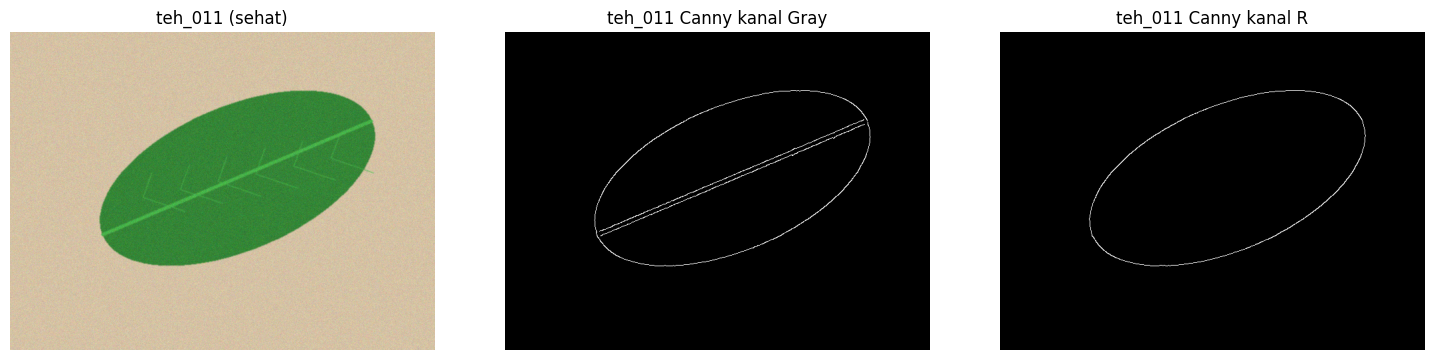

In [14]:
baris, panel, judul = [], [], []
for _, d in label[label.kelas == "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    dalam = cv2.erode(md, np.ones((7, 7), np.uint8)) > 0       # bagian dalam daun
    for kanal, g in [("Gray", cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)), ("R", pra_[:, :, 2])]:
        e = tepi_canny(g)
        baris.append([d.kondisi_cahaya, kanal, int(((e > 0) & dalam).sum())])
        if d.nama_file == "teh_011.png":
            panel.append(e); judul.append(f"teh_011 Canny kanal {kanal}")
sehat = pd.DataFrame(baris, columns=["kondisi", "kanal", "piksel_tepi_di_dalam_daun"])
print(sehat.pivot_table(index="kondisi", columns="kanal", values="piksel_tepi_di_dalam_daun").round(1))
tampil([muat("teh_011.png")[0]] + panel, ["teh_011 (sehat)"] + judul, ukuran=(15, 3.6))
plt.savefig("../hasil/p5_tepi_sehat.png", dpi=130, bbox_inches="tight")

### Langkah 2.6 Tabel keputusan (Tabel 8) dan Langkah 2.7 checkpoint
Tabel 8 diisi di laporan (Bagian 5) dengan merujuk Tabel 6, 7, keluaran Kode 2.2 dan 2.3 serta `canny_persentil`.

Checkpoint (jalankan di terminal repository, bukan di Colab):
```
git add . && git commit -m "P5: deteksi tepi (Sobel, Prewitt, LoG, Canny)"
git tag v0.2-tepi && git push && git push --tags
```